# Lab 6 – Responsible AI HS2026 (P06)
**Author:** Jann Erhardt (erharjan) · individual submission

Scaffold only: fill in the `TODO`s yourself. Paste results/plots into the answer PDF (`Lab6_erharjan_template.pdf`).

The *Sanity checks* cells fail until the functions above them are implemented – they only test properties, not the lab results.

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = 'loan_applicants_test_set.csv'  # columns: p (score), g (0 = women, 1 = men), Y (1 = paid back)
df = pd.read_csv(DATA)

YEARS = 5        # loan duration
Z = 0.10         # annual interest rate
THRESHOLDS = np.round(np.linspace(0.5, 1.0, 51), 2)  # 0.50, 0.51, ..., 1.00
GROUPS = {0: 'women', 1: 'men'}

df.head()

,p,g,Y
0,0.343231,0,0
1,0.730046,0,0
2,0.526888,0,1
3,0.454292,0,1
4,0.213089,0,0


## (a) Score distributions and calibration

In [20]:
def group_overview(df, score_col='p'):
    """Table with N, mean score and base rate (mean Y) per group and for all."""
    df_grouped = df.groupby('g').agg(
        N=('Y', 'size'),
        mean_score=(score_col, 'mean'),
        base_rate=('Y', 'mean')
    ).reset_index()
    df_grouped['group'] = df_grouped['g'].map(GROUPS)
    overall = pd.DataFrame({
        'g': ['all'],
        'N': [df.shape[0]],
        'mean_score': [df[score_col].mean()],
        'base_rate': [df['Y'].mean()],
        'group': ['all']
    })
    return pd.concat([df_grouped, overall], ignore_index=True)[['group', 'N', 'mean_score', 'base_rate']]


def plot_score_distributions(df, score_col='p', bins=50):
    """Histogram of the score per group (same bins, comparable scale)."""
    fig, ax = plt.subplots(figsize=(8, 6))
    for g, group_name in GROUPS.items():
        subset = df[df['g'] == g]
        ax.hist(subset[score_col], bins=bins, alpha=0.5, label=group_name, density=True)
    ax.set_xlabel('Score')
    ax.set_ylabel('Density')
    ax.legend()
    plt.show()


def calibration_plot(df, score_col='p', n_bins=10):
    """Per group: mean score per bin (x) vs. mean Y per bin (y), plus the diagonal."""
    fig, ax = plt.subplots(figsize=(8, 6))
    for g, group_name in GROUPS.items():
        subset = df[df['g'] == g]
        bins = np.linspace(0, 1, n_bins + 1)
        bin_indices = np.digitize(subset[score_col], bins) - 1
        bin_means = [subset[score_col][bin_indices == i].mean() for i in range(n_bins)]
        bin_targets = [subset['Y'][bin_indices == i].mean() for i in range(n_bins)]
        ax.plot(bin_means, bin_targets, marker='o', label=group_name)
    ax.plot([0, 1], [0, 1], 'k--', label='Perfect calibration')
    ax.set_xlabel('Mean score per bin')
    ax.set_ylabel('Mean Y per bin')
    ax.legend()
    plt.show()

In [21]:
group_overview(df)

,group,N,mean_score,base_rate
0,women,10000,0.406324,0.4059
1,men,10000,0.496220,0.4929
2,all,20000,0.451272,0.4494


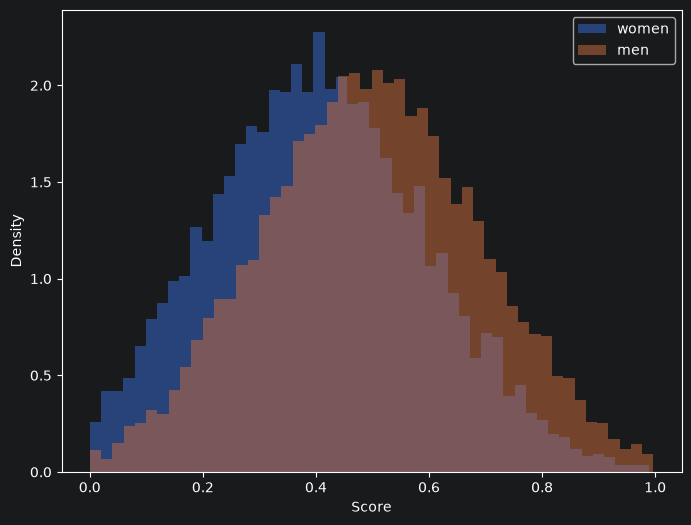

In [22]:
plot_score_distributions(df)

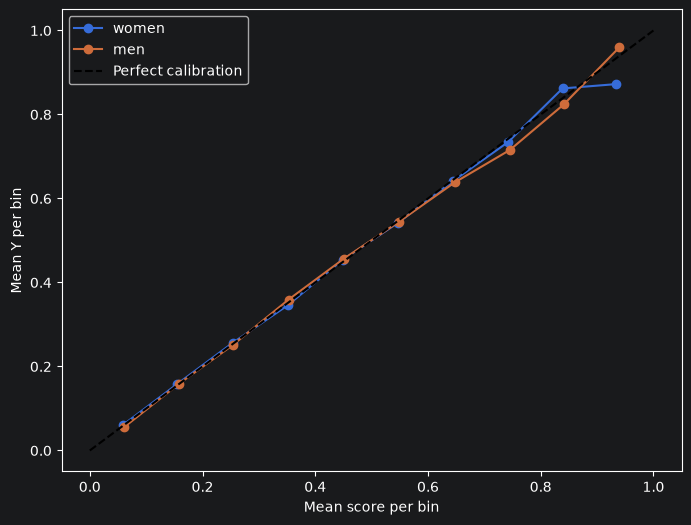

In [23]:
calibration_plot(df)

## (b) DM and DS utility, Pareto plot

In [24]:
def bank_utility_matrix(H=1, z=Z, years=YEARS):
    """2x2 array U[d, y]: profit of the bank (compound interest)."""
    return np.array([
        [0.0, 0.0],
        [-H,  H * ((1 + z) ** years - 1)],
    ])


V = np.array([
    [0, 0],
    [1, 1],
])

In [25]:
def evaluate_rule(df, t_f, t_m, score_col='p', U=None, V_ds=None):
    """Apply D = 1 iff score > t_g (t_f for women, t_m for men).
    Return (profit, FS) with FS = -|E(V | m) - E(V | f)|."""
    U = bank_utility_matrix() if U is None else np.asarray(U)
    V_ds = V if V_ds is None else np.asarray(V_ds)

    g = df['g'].to_numpy()
    y = df['Y'].to_numpy().astype(int)
    t = np.where(g == 1, t_m, t_f)                      # each applicant gets the threshold of their group
    d = (df[score_col].to_numpy() > t).astype(int)      # decision per applicant

    profit = U[d, y].sum()                              # bank: realised profit, summed over all applicants
    v = V_ds[d, y]                                      # applicant: benefit per individual
    fs = -abs(v[g == 1].mean() - v[g == 0].mean())      # E(V|m) vs. E(V|f)
    return profit, fs


def evaluate_grid(df, thresholds=THRESHOLDS, score_col='p', U=None, V_ds=None):
    """DataFrame with columns t_f, t_m, profit, FS for all len(thresholds)**2 combinations."""
    rows = []
    for t_f in thresholds:
        for t_m in thresholds:
            profit, fs = evaluate_rule(df, t_f, t_m, score_col, U, V_ds)
            rows.append({'t_f': t_f, 't_m': t_m, 'profit': profit, 'FS': fs})
    return pd.DataFrame(rows)


def pareto_front(results, x='FS', y='profit'):
    """Rows of `results` that no other row dominates (both x and y are maximized), sorted by x."""
    xs = results[x].to_numpy()
    ys = results[y].to_numpy()
    # entry [i, j]: does rule j dominate rule i?
    at_least_as_good = (xs[None, :] >= xs[:, None]) & (ys[None, :] >= ys[:, None])
    strictly_better = (xs[None, :] > xs[:, None]) | (ys[None, :] > ys[:, None])
    dominated = (at_least_as_good & strictly_better).any(axis=1)
    return results[~dominated].sort_values(x)

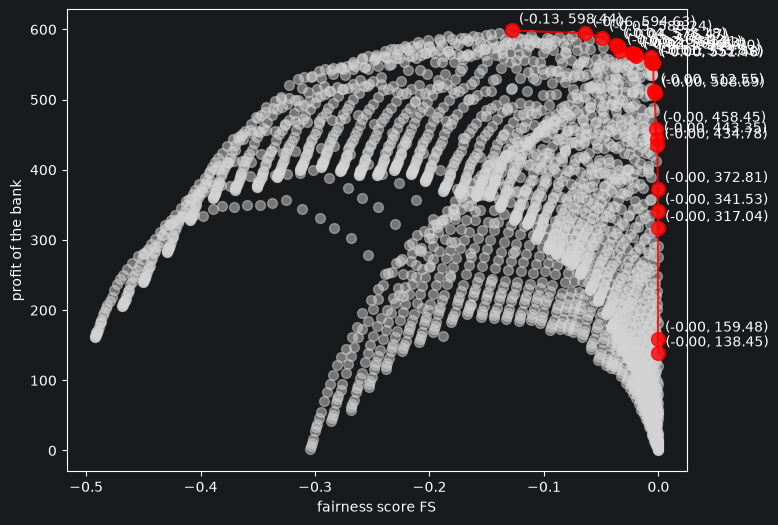

In [26]:
results = evaluate_grid(df)
front = pareto_front(results)
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(results['FS'], results['profit'], c='lightgray', s=50, alpha=0.5)
ax.scatter(front['FS'], front['profit'], c='red', s=100, alpha=0.8)
for i in range(len(front)):
    ax.annotate(f'({front.iloc[i]["FS"]:.2f}, {front.iloc[i]["profit"]:.2f})', (front.iloc[i]['FS'], front.iloc[i]['profit']), xytext=(5, 5), textcoords='offset points')
    if i < len(front) - 1:
        ax.plot([front.iloc[i]['FS'], front.iloc[i + 1]['FS']], [front.iloc[i]['profit'], front.iloc[i + 1]['profit']], c='red', alpha=0.8)
ax.set_xlabel('fairness score FS'); ax.set_ylabel('profit of the bank')
plt.show()

In [31]:
print(front)

       t_f   t_m     profit      FS
469   0.59  0.60  598.44189 -0.1280
473   0.59  0.64  594.62738 -0.0638
474   0.59  0.65  588.23944 -0.0493
475   0.59  0.66  578.17762 -0.0371
423   0.58  0.65  576.46973 -0.0354
371   0.57  0.64  569.02459 -0.0337
424   0.58  0.66  566.40791 -0.0232
476   0.59  0.67  564.63203 -0.0209
372   0.57  0.65  562.63665 -0.0192
477   0.59  0.68  561.29664 -0.0069
530   0.60  0.70  553.82679 -0.0068
529   0.60  0.69  552.56249 -0.0046
581   0.61  0.70  551.48058 -0.0044
685   0.63  0.72  512.54860 -0.0043
737   0.64  0.73  508.68771 -0.0033
841   0.66  0.75  458.44970 -0.0023
945   0.68  0.77  443.34770 -0.0014
997   0.69  0.78  434.78047 -0.0009
1101  0.71  0.80  372.80521 -0.0005
1153  0.72  0.81  341.53319 -0.0004
1205  0.73  0.82  317.04015 -0.0003
1620  0.81  0.89  159.47912 -0.0003
1672  0.82  0.90  138.44821 -0.0000


### Sanity checks (b)

In [27]:
# toy example: maximize both columns -> A, B, C are Pareto-optimal; D is dominated by B, E by A
toy = pd.DataFrame({'name': list('ABCDE'),
                    'FS':     [-0.3, -0.1, 0.0, -0.2, -0.3],
                    'profit': [10.0,  8.0, 5.0,  7.0,  6.0]})
assert set(pareto_front(toy)['name']) == {'A', 'B', 'C'}

# nobody accepted (score > 1.0 is impossible) -> no profit and perfectly fair
profit, fs = evaluate_rule(df, 1.0, 1.0)
assert profit == 0 and fs == 0

res = evaluate_grid(df)
assert len(res) == 51 * 51
assert (res['FS'] <= 0).all() and (res['FS'] >= -1).all()
print('ok')

ok


## (c) Reading the Pareto plot
a. maximum profit · b. maximum profit under demographic parity · c. half the unfairness of a.

In [44]:
def analytic_threshold(z=Z, years=YEARS):
    """Threshold p0 from the utility matrix, as in P05 exercise 1."""
    return 1 / ((1 + z) ** years)

print(f'Maximum profit: {front["profit"].max()} at thresholds t_f={front.loc[front["profit"].idxmax(), "t_f"]}, t_m={front.loc[front["profit"].idxmax(), "t_m"]}, FS={front.loc[front["profit"].idxmax(), "FS"]}')
print(f'Best rule with FS == 0: t_f={front.loc[front["FS"].idxmax(), "t_f"]}, t_m={front.loc[front["FS"].idxmax(), "t_m"]}, profit={front.loc[front["FS"].idxmax(), "profit"]}')
print(f'Best rule with FS >= FS_a / 2: t_f={front.loc[front["FS"] >= front["FS"].min() / 2, "t_f"].iloc[0]}, t_m={front.loc[front["FS"] >= front["FS"].min() / 2, "t_m"].iloc[0]}, profit={front.loc[front["FS"] >= front["FS"].min() / 2, "profit"].iloc[0]}, FS={front.loc[front["FS"] >= front["FS"].min() / 2, "FS"].iloc[0]}')

print(f'Analytic threshold: {analytic_threshold()}')

Maximum profit: 598.4418900000019 at thresholds t_f=0.59, t_m=0.6, FS=-0.128
Best rule with FS == 0: t_f=0.82, t_m=0.9, profit=138.44821000000013
Best rule with FS >= FS_a / 2: t_f=0.59, t_m=0.64, profit=594.6273800000016, FS=-0.0638
Analytic threshold: 0.6209213230591549


In [39]:
100 - 138.44821000000013 * 100 / 598.4418900000019

76.86522078192091

## (d) Biased prediction for men: $p_2 = \sqrt{p}$

In [45]:
def distort(df):
    """Copy of df with p replaced by sqrt(p) for men (g = 1); women unchanged."""
    df2 = df.copy()
    df2.loc[df2['g'] == 1, 'p'] = np.sqrt(df2.loc[df2['g'] == 1, 'p'])
    return df2


def accepted(df, t_f, t_m, score_col='p'):
    """Set of row indices with D = 1 under the rule (t_f, t_m)."""
    g = df['g'].to_numpy()
    t = np.where(g == 1, t_m, t_f)
    d = (df[score_col].to_numpy() > t).astype(int)
    return set(df.index[d == 1])

### Sanity checks (d)

In [46]:
df2 = distort(df)
assert df2 is not df and len(df2) == len(df)
assert np.allclose(df2.loc[df.g == 0, 'p'], df.loc[df.g == 0, 'p'])
assert np.allclose(df2.loc[df.g == 1, 'p'] ** 2, df.loc[df.g == 1, 'p'])
assert accepted(df, 1.0, 1.0) == set()
print('ok')

ok


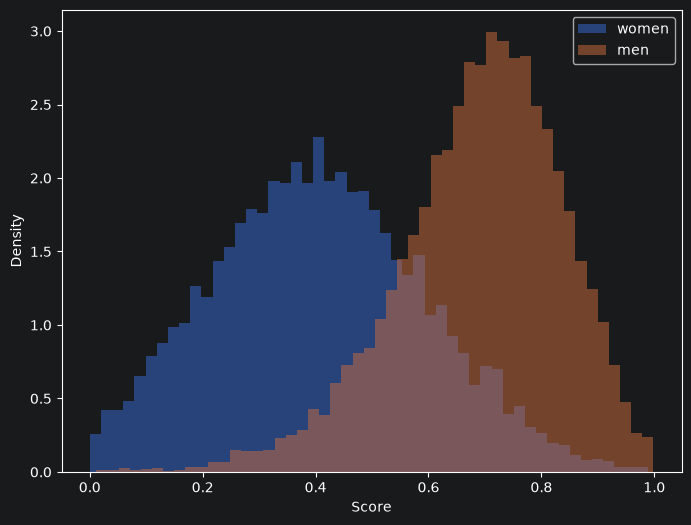

In [47]:
plot_score_distributions(df2)

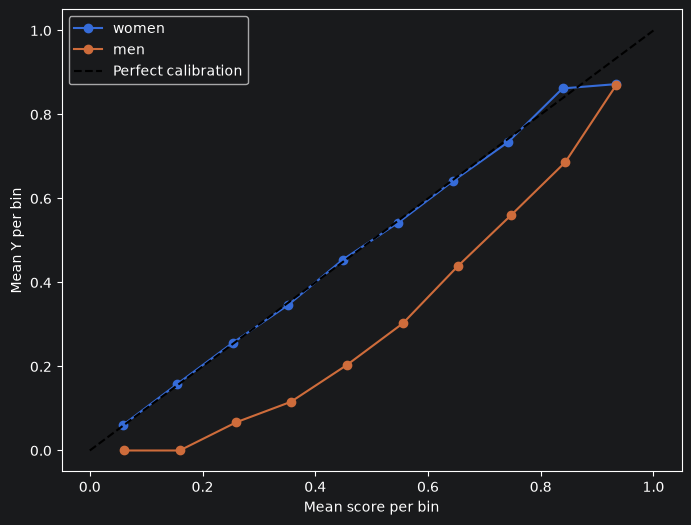

In [48]:
calibration_plot(df2)

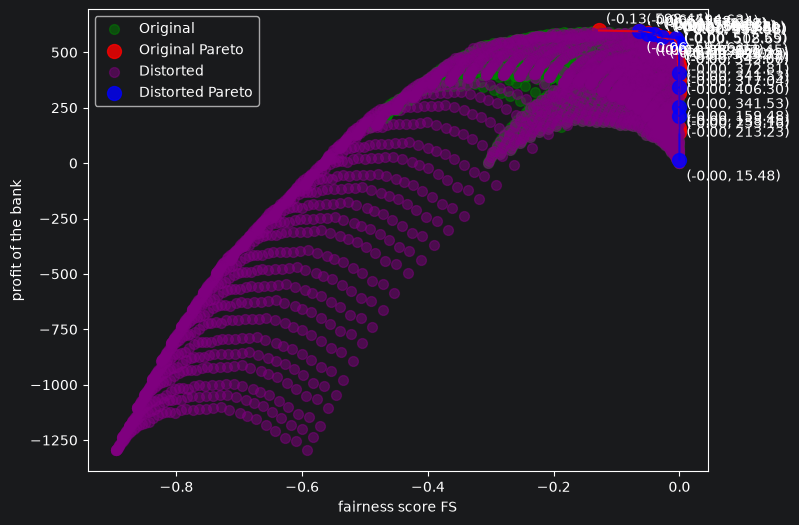

In [50]:
results2 = evaluate_grid(df2)
front2 = pareto_front(results2)
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(results['FS'], results['profit'], c='green', s=50, alpha=0.5, label='Original')
ax.scatter(front['FS'], front['profit'], c='red', s=100, alpha=0.8, label='Original Pareto')
ax.scatter(results2['FS'], results2['profit'], c='purple', s=50, alpha=0.5, label='Distorted')
ax.scatter(front2['FS'], front2['profit'], c='blue', s=100, alpha=0.8, label='Distorted Pareto')
for i in range(len(front)):
    ax.annotate(f'({front.iloc[i]["FS"]:.2f}, {front.iloc[i]["profit"]:.2f})', (front.iloc[i]['FS'], front.iloc[i]['profit']), xytext=(5, 5), textcoords='offset points')
    if i < len(front) - 1:
        ax.plot([front.iloc[i]['FS'], front.iloc[i + 1]['FS']], [front.iloc[i]['profit'], front.iloc[i + 1]['profit']], c='red', alpha=0.8)
for i in range(len(front2)):
    ax.annotate(f'({front2.iloc[i]["FS"]:.2f}, {front2.iloc[i]["profit"]:.2f})', (front2.iloc[i]['FS'], front2.iloc[i]['profit']), xytext=(5, -15), textcoords='offset points')
    if i < len(front2) - 1:
        ax.plot([front2.iloc[i]['FS'], front2.iloc[i + 1]['FS']], [front2.iloc[i]['profit'], front2.iloc[i + 1]['profit']], c='blue', alpha=0.8)
ax.set_xlabel('fairness score FS'); ax.set_ylabel('profit of the bank')
ax.legend()
plt.show()

In [55]:
def accepted(df, t_f, t_m, score_col='p'):
    """Set of row indices with D = 1 under the rule (t_f, t_m)."""
    t = np.where(df['g'] == 1, t_m, t_f)
    return set(df.index[df[score_col].to_numpy() > t])


# frontiers of the original and the distorted data (skip these lines if you already have them)
front = pareto_front(evaluate_grid(df))
df2 = distort(df)
front2 = pareto_front(evaluate_grid(df2))

# profit and FS live on very different scales -> measure distances between locations in normalized units
span_profit = front['profit'].max() - front['profit'].min()
span_fs = front['FS'].max() - front['FS'].min()

rows = []
for loc, (_, o) in enumerate(front.iterrows(), start=1):
    # the same location on the distorted frontier = its nearest point in (FS, profit)
    dist = np.hypot((front2['profit'] - o['profit']) / span_profit,
                    (front2['FS'] - o['FS']) / span_fs)
    d = front2.loc[dist.idxmin()]

    a_orig = accepted(df, o['t_f'], o['t_m'])
    a_dist = accepted(df2, d['t_f'], d['t_m'])
    diff = a_orig ^ a_dist                                   # accepted under one rule but not the other
    n_men = int((df.loc[list(diff), 'g'] == 1).sum())

    rows.append({
        'Loc.': loc,
        'profit orig / dist': f"{o['profit']:.1f} / {d['profit']:.1f}",
        'FS orig / dist': f"{o['FS']:.4f} / {d['FS']:.4f}",
        'original t_f / t_m': f"{o['t_f']:.2f} / {o['t_m']:.2f}",
        'distorted t_f / t_m': f"{d['t_f']:.2f} / {d['t_m']:.2f}",
        'dist t_m²': f"{d['t_m'] ** 2:.4f}",
        '# accepted orig / dist': f'{len(a_orig)} / {len(a_dist)}',
        'same individuals?': 'yes' if not diff else f'no – {len(diff)} differ ({n_men} men)',
        'Δ location': f'{dist.min():.3f}',
    })

pd.set_option('display.width', 250)
print(pd.DataFrame(rows).to_string(index=False))

 Loc. profit orig / dist    FS orig / dist original t_f / t_m distorted t_f / t_m dist t_m² # accepted orig / dist          same individuals? Δ location
    1      598.4 / 594.6 -0.1280 / -0.0638        0.59 / 0.60         0.59 / 0.80    0.6400            4618 / 3976  no – 642 differ (642 men)      0.502
    2      594.6 / 594.6 -0.0638 / -0.0638        0.59 / 0.64         0.59 / 0.80    0.6400            3976 / 3976                        yes      0.000
    3      588.2 / 582.9 -0.0493 / -0.0499        0.59 / 0.65         0.58 / 0.80    0.6400            3831 / 4115  no – 284 differ (145 men)      0.013
    4      578.2 / 582.3 -0.0371 / -0.0412        0.59 / 0.66         0.59 / 0.81    0.6561            3709 / 3750    no – 41 differ (41 men)      0.033
    5      576.5 / 582.3 -0.0354 / -0.0412        0.58 / 0.65         0.59 / 0.81    0.6561            3970 / 3750   no – 220 differ (81 men)      0.047
    6      569.0 / 570.5 -0.0337 / -0.0273        0.57 / 0.64         0.58 / 0.81 

## (e) Generalization
Answer in prose in the PDF. Optional: test your claim with other distortions of the men's scores.

In [ ]:
# optional experiments for (e)